In [ ]:
import marimo as mo

# Laplacian Eigenmaps and Logistic Regression

*August 4 2026*
*Training Workshop: Introduction to Deep Graph Learning*
*Ingo Scholtes, CAIDAS, Julius-Maximilians-Universität Würzburg (JMU), Germany*

In a first practice notebook addressing machine learning in complex networks, we combine Laplacian eigenmaps to obtain a Euclidean representation of a graph with logistic regression to implement supervised node classification and supervised link prediction.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy as sp
import seaborn as sns
from sklearn import metrics
from sklearn.datasets import make_circles
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

import pathpyG as pp

plt.style.use('default')
sns.set_style("whitegrid")

## Supervised Node Classification

As a simple example for (binary) node classification, we use the Karate club network which contains ground truth binary class labels for nodes. We can print the network to get a description of the underlying data set.

In [ ]:
n = pp.io.read_netzschleuder_graph(name='karate', network='77')
print(n)

Undirected graph with 34 nodes and 77 edges
{   'Edge Attributes': {},
    'Graph Attributes': {   'analyses_average_degree': "<class 'float'>",
                            'analyses_degree_assortativity': "<class 'float'>",
                            'analyses_degree_std_dev': "<class 'float'>",
                            'analyses_diameter': "<class 'int'>",
                            'analyses_edge_properties': "<class 'list'>",
                            'analyses_edge_reciprocity': "<class 'float'>",
                            'analyses_global_clustering': "<class 'float'>",
                            'analyses_hashimoto_radius': "<class 'float'>",
                            'analyses_is_bipartite': "<class 'bool'>",
                            'analyses_is_directed': "<class 'bool'>",
                            'analyses_knn_proj_1': "<class 'float'>",
                            'analyses_knn_proj_2': "<class 'float'>",
                            'analyses_largest_compo

In the description of the data, we see that there is an integer vertex property `groups` that contains the ground truth classes that we can use to train and validate our logistic regression classifier. Let's plot the network, coloring nodes according to the class labels.

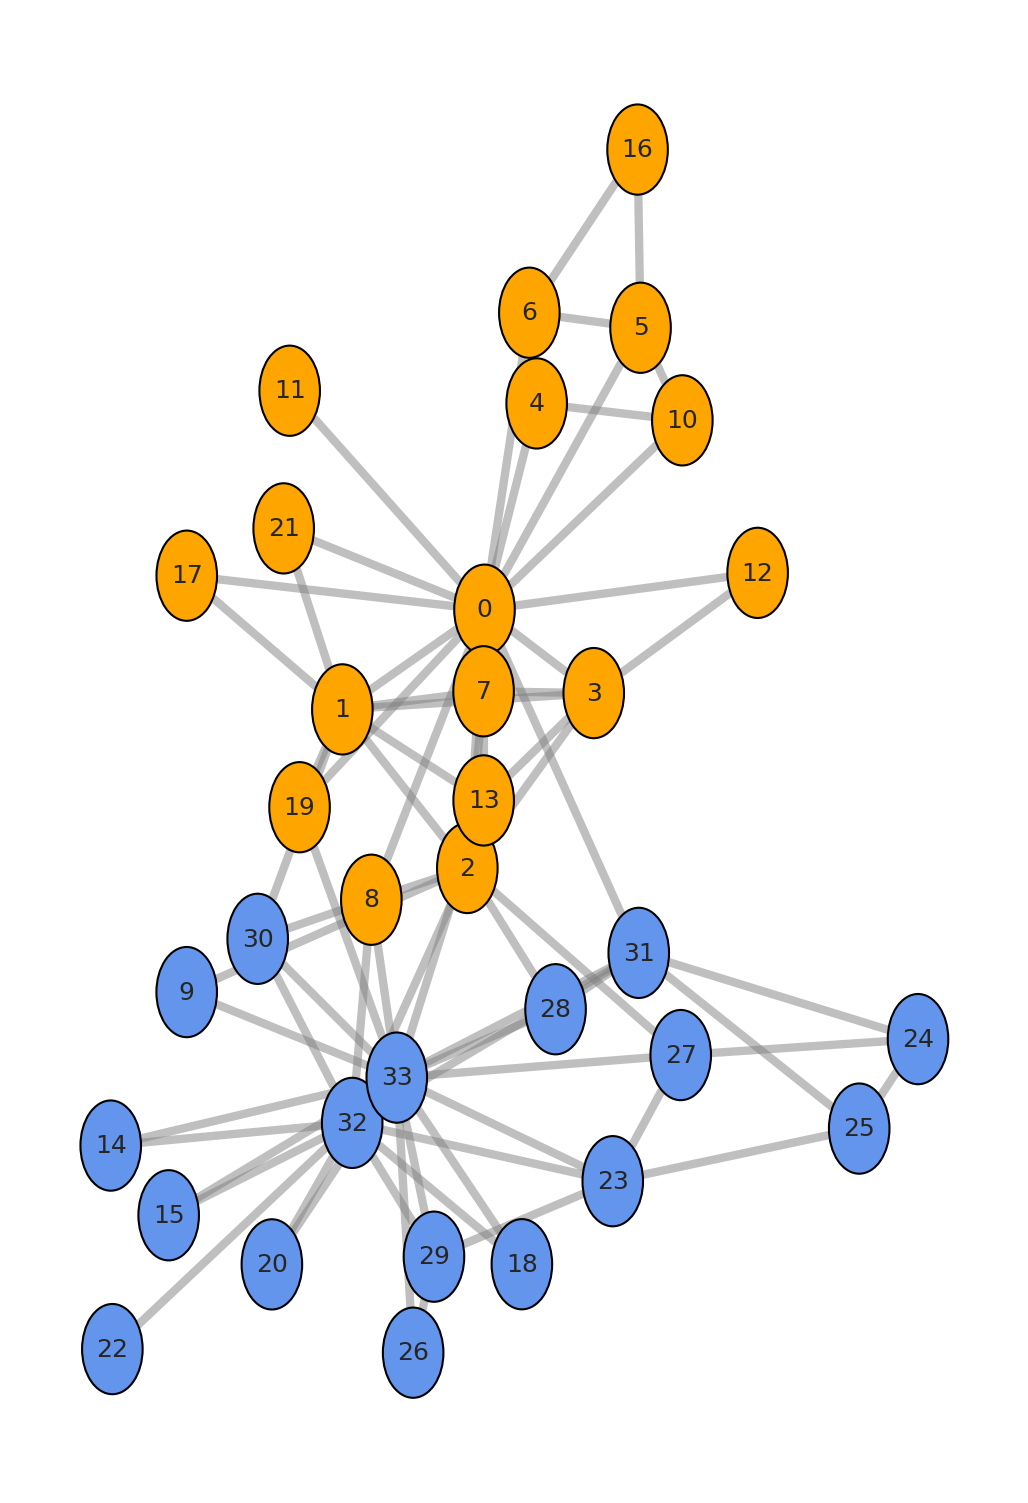

In [ ]:
_colors = {}
_colors[0] = 'orange'
_colors[1] = 'CornflowerBlue'
_node_colors = {v: _colors[n['node_groups', v].item() - 1] for v in n.nodes}
# use zero-based group indices to facilitate binary classification
node_labels = {v: str(v) for v in n.nodes}
plot_style = {}
plot_style['edge_opacity'] = 0.5
plot_style['edge_color'] = 'gray'
plot_style['node_opacity'] = 1.0
plot_style['node_size'] = 15
plot_style['node_color'] = _node_colors
plot_style['node_label'] = node_labels
fr_karate = pp.layout(n, layout='Fruchterman-Reingold', seed=1, iterations=2500)
pp.plot(n, **plot_style, layout=fr_karate, backend='matplotlib', width='400px', height='600px');

We store the nodes as well as the group information in a `pandas` data frame. We can easily split this into a training and test set using the `sklearn` function `train_test_split`:

In [ ]:
_nodes = [(v, n['node_groups', v].item() - 1) for v in n.nodes]
data = pd.DataFrame(_nodes, columns=['v', 'group'])
train, test = train_test_split(data, test_size=0.3)

In [ ]:
print(train)

     v  group
3    3      0
29  29      1
30  30      1
24  24      1
32  32      1
..  ..    ...
9    9      1
6    6      0
8    8      0
4    4      0
10  10      0

[23 rows x 2 columns]


We now need represent the graph in a Euclidean space. For this, we can, for instance, use the Laplacian eigenmaps, i.e. we use the eigenvectors of the Laplacian matrix (see [Networks, Adjacency and Laplacian Matrices](../../getting_started/network_matrices/)) to get an embedding of nodes. Using the function `Graph.laplacian()`, this can be done as follows:

In [ ]:
def laplacian_embedding(network, laplacian, d=None):
    """Function that returns a vector representation of all nodes based on the entries of eigenvectors of the laplacian."""
    if d is None:
        d = network.n - 1
    ew, ev = sp.linalg.eig(laplacian.todense())
    index = np.argsort(ew)[1:]
    ev = ev[:, index]
    ew = ew[index]  # get eigenvectors and eigenvalues in ascending order, skipping the first
    vecs = {}
    for v in network.nodes:
        idx = network.mapping.to_idx(v)
        vecs[v] = ev[idx, :d].real
        for i in range(d):  #ev = normalize(ev, p=2)
            vecs[v][i] = vecs[v][i] / ew[i].real
    return vecs  # embedding x_ of node i in m-dimensional vector space is given by  # i-th component in the first m eigenvectors  # (ignoring the eigenvector corrresponding to zero eigenvalue)  #embedding = ev[:,:d]

The following function takes an embedding (i.e. a dictionary mapping vectors to nodes) and adds the feature dimensions to an existing `pandas` data frame. We use columns $x_0, \ldots, x_{d-1}$ to store $d$ feature dimensions:

In [ ]:
def assign_features(embedding, df):
    """Assigns feature columns to a data frame."""
    for index, row in df.iterrows():
        f = embedding[row['v']]
        for i in range(len(f)):
            df.loc[index, 'x{0}'.format(i)] = f[i]

We can now assign two-dimensional vector representations to the nodes in the training and test set:

In [ ]:
_embedding = laplacian_embedding(n, n.laplacian(), d=2)
assign_features(_embedding, train)
assign_features(_embedding, test)
print(train)

     v  group        x0        x1
3    3      0  0.126561  0.127113
29  29      1 -0.351028 -0.033174
30  30      1 -0.153105  0.024574
24  24      1 -0.313264  0.032920
32  32      1 -0.289812 -0.064577
..  ..    ...       ...       ...
9    9      1 -0.184742  0.063052
6    6      0  0.689695 -0.229263
8    8      0 -0.106209  0.024655
4    4      0  0.607943 -0.142231
10  10      0  0.607943 -0.142230

[23 rows x 4 columns]


We plot the features and class labels of nodes in the training set (adding the nodes in the test set in gray):

In [ ]:
sns.scatterplot(x='x0', y='x1', data=train, hue='group')
sns.scatterplot(x='x0', y='x1', data=test, color='lightgrey')
plt.tight_layout()

We can now use the data in the training set to infer the parameters of a logistic regression model:

In [ ]:
logreg = LogisticRegression()
logreg = logreg.fit(train[['x0', 'x1']], train['group'])
print(logreg.coef_)

[[-2.07841901 -0.11414755]]


We can now use the model to predict the classes using the node features in the test set:

In [ ]:
test['predicted'] = logreg.predict(test[['x0', 'x1']])

Let us plot the predictions for the test set along with the fitted decision boundary of the logistic regression classifier.

In [ ]:
_min_x = min(train['x0'].min(), test['x0'].min())
_min_y = min(train['x1'].min(), test['x1'].min())
_max_x = max(train['x0'].max(), test['x0'].max())
_max_y = max(train['x1'].max(), test['x1'].max())
_x_mesh, _y_mesh = np.meshgrid(np.linspace(_min_x, _max_x, 200), np.linspace(_min_y, _max_y, 200))
_class_probs = logreg.decision_function(np.c_[_x_mesh.ravel(), _y_mesh.ravel()])
_z = np.array(_class_probs).reshape(_x_mesh.shape)
test['predicted'] = logreg.predict(test[['x0', 'x1']])
#print(logits)
_fig, _ax = plt.subplots()
#class_probs = torch.softmax(logits, dim=0)
plt.pcolormesh(_x_mesh, _y_mesh, _z > 0, cmap=plt.cm.Paired, alpha=0.5)
sns.scatterplot(x='x0', y='x1', data=train, color='lightgray', alpha=0.5)
sns.scatterplot(x='x0', y='x1', data=test, hue='group')
plt.tight_layout()

/media/vineetb/delta/projects/pathpyG/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


For this (admittedly simple) example, we obtain a relatively high accuracy. We could probably further improve this if we were to use a higher-dimensional embedding (which we did not do here for illustrative purposes).

In [ ]:
metrics.balanced_accuracy_score(logreg.predict(test[['x0', 'x1']]), test[['group']])

0.6111111111111112

## Supervised learning  in networks with non-linear patterns

Above, we have used logistic regression to address supervised node classification. Like other linear classification techniques (e.g. support vector machines without non-linear kernels or a perceptron model), logistic regression gives rise to a linear decision boundary, i.e. it is not expressive enough to address machine learning in many real data sets. Let us motivate this in a synthetic example for a network, where node classification requires non-linear classification techniques.

We will generate a network based on the circles data set in sklearn:

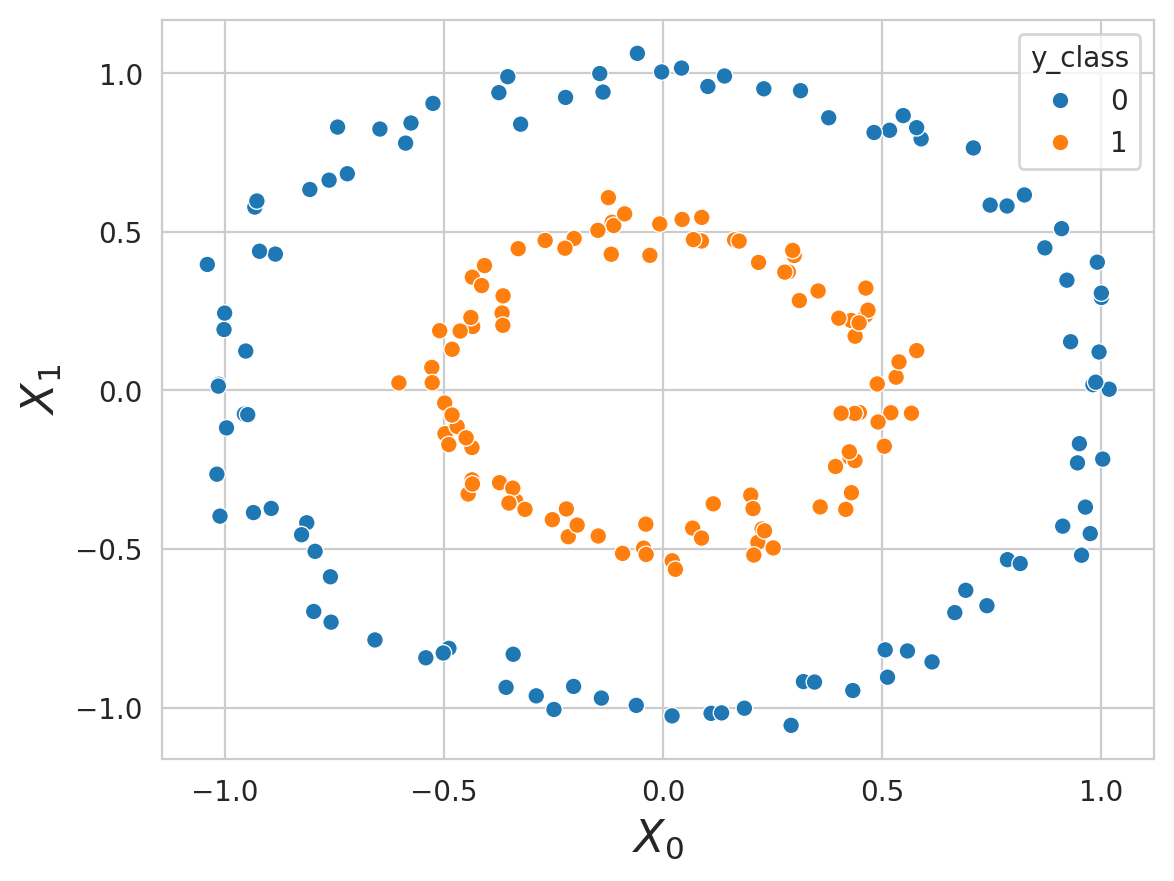

In [ ]:
x, c = make_circles(n_samples=200, noise=0.05, factor=0.5)
data_1 = pd.DataFrame({'x0': x[:, 0], 'x1': x[:, 1], 'y_class': c})
sns.scatterplot(x='x0', y='x1', data=data_1, hue='y_class')
plt.xlabel('$X_0$', fontsize=16)
plt.ylabel('$X_1$', fontsize=16)

We now generate links based on a soft rule that builds on the Euclidean distance between the points above, i.e. each node correspond to a point (falling in two different groups according to the colors) and we then add links with a probability that depends on the distance.

In [ ]:
def euclidean_dist(x, y):
    """Computes the Euclidean distance between two points."""
    return np.linalg.norm(x - y)

def soft_rule(dist, **kwargs):
    """Determine probabilistically whether a connection forms based on distance."""
    p = kwargs['beta'] * np.exp(-dist / kwargs['alpha'])
    if np.random.random() <= p:
        return True
    else:
        return False
node_ids = [str(i) for i in range(len(data_1))]
pos = {str(i): np.array([row['x0'], row['x1']]) for i, row in data_1.iterrows()}
edges = []
for v in node_ids:
    for w in node_ids:
        if soft_rule(euclidean_dist(pos[v], pos[w]), alpha=0.05, beta=70) and v != w:
            edges.append((v, w))
net = pp.Graph.from_edge_list(edges, mapping=pp.IndexMap(node_ids)).to_undirected()
print(net)

Undirected graph with 200 nodes and 1250 edges
{'Edge Attributes': {}, 'Graph Attributes': {'num_nodes': "<class 'int'>"}, 'Node Attributes': {}}


In [ ]:
_colors = {}
_colors[0] = 'orange'
_colors[1] = 'CornflowerBlue'
g_class = {str(i): c[i] for i in range(len(data_1))}
_node_colors = {v: _colors[g_class[v]] for v in net.nodes}
pp.plot(net, edge_color='grey', node_color=_node_colors);

<iframe srcdoc='<style>
.label-text {
 fill: #969595;
 font-size: 16px;
 font-family: sans-serif;
}
</style>

<div id = "xebb28c157fc744878600d97f92488d65"> </div>
<script charset="utf-8">
function render_plot_8fea130973e241308538771e5a2f020c() {
 const d3 = window.d3;
 if (!d3) { console.error('D3 not loaded'); return; }
const data = {"nodes": [{"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "0"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "1"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "2"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "3"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "4"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "5"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "6"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "7"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "8"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "9"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "10"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "11"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "12"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "13"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "14"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "15"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "16"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "17"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "18"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "19"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "20"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "21"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "22"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "23"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "24"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "25"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "26"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "27"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "28"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "29"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "30"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "31"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "32"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "33"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "34"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "35"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "36"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "37"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "38"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "39"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "40"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "41"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "42"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "43"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "44"}, {"color": "#6495ed", "size": 15, "opacity": 0.75, "image": null, "uid": "45"}, {"color": "#6495ed", "size":

Let us now create a training-test split of the nodes and assign the features based on a Laplacian embedding:

In [ ]:
_nodes = [(v, g_class[v]) for v in net.nodes]
data_2 = pd.DataFrame(_nodes, columns=['v', 'group'])
train_1, test_1 = train_test_split(data_2, test_size=0.3)
print(train_1)

       v  group
9      9      0
27    27      0
84    84      0
197  197      0
104  104      0
..   ...    ...
165  165      0
176  176      1
93    93      1
75    75      1
24    24      0

[140 rows x 2 columns]


In [ ]:
_embedding = laplacian_embedding(net, net.laplacian(), d=2)
assign_features(_embedding, train_1)
assign_features(_embedding, test_1)
assign_features(_embedding, data_2)

Let's plot the resulting embedding of the nodes:

In [ ]:
sns.scatterplot(x='x0', y='x1', data=data_2, hue='group')
plt.tight_layout()

We now apply a logistic regression model:

In [ ]:
logreg_1 = LogisticRegression()
logreg_1 = logreg_1.fit(train_1[['x0', 'x1']], train_1['group'].to_numpy())
print(logreg_1.coef_)

[[ 4.22178035 -1.35003402]]


In [ ]:
_min_x = data_2['x0'].min()
_min_y = data_2['x1'].min()
_max_x = data_2['x0'].max()
_max_y = data_2['x1'].max()
_x_mesh, _y_mesh = np.meshgrid(np.linspace(_min_x, _max_x, 200), np.linspace(_min_y, _max_y, 200))
_class_probs = logreg_1.decision_function(np.c_[_x_mesh.ravel(), _y_mesh.ravel()])
_z = np.array(_class_probs).reshape(_x_mesh.shape)
test_1['predicted'] = logreg_1.predict(test_1[['x0', 'x1']])
_fig, _ax = plt.subplots()
plt.pcolormesh(_x_mesh, _y_mesh, _z > 0, cmap=plt.cm.Paired, alpha=0.5)
sns.scatterplot(x='x0', y='x1', data=train_1, color='lightgray', alpha=0.5)
sns.scatterplot(x='x0', y='x1', data=test_1, hue='group')
plt.tight_layout()

/media/vineetb/delta/projects/pathpyG/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


Clearly, this simple linear model is not able to capture this non-linear pattern. In the next three notebooks, we will show how we can address this using neural networks.